<a href="https://colab.research.google.com/github/KishanSadeesh/DataScience/blob/main/hierarchical_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
data = pd.read_csv("Customer_Behaviour.csv")
data

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [3]:
X = data[[
    "Age",
    "EstimatedSalary",
    "Purchased"
]]
X

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

In [6]:
clusters = kmeans.fit_predict(X)
data["Cluster"] = clusters

In [7]:
data

,User ID,Gender,Age,EstimatedSalary,Purchased,Cluster
0,15624510,Male,19,19000,0,0
1,15810944,Male,35,20000,0,0
2,15668575,Female,26,43000,0,0
3,15603246,Female,27,57000,0,1
4,15804002,Male,19,76000,0,1
...,...,...,...,...,...,...
395,15691863,Female,46,41000,1,0
396,15706071,Male,51,23000,1,0
397,15654296,Female,50,20000,1,0
398,15755018,Male,36,33000,0,0


In [8]:
data.head(40)

,User ID,Gender,Age,EstimatedSalary,Purchased,Cluster
0,15624510,Male,19,19000,0,0
1,15810944,Male,35,20000,0,0
2,15668575,Female,26,43000,0,0
3,15603246,Female,27,57000,0,1
4,15804002,Male,19,76000,0,1
5,15728773,Male,27,58000,0,1
6,15598044,Female,27,84000,0,1
7,15694829,Female,32,150000,1,2
8,15600575,Male,25,33000,0,0
9,15727311,Female,35,65000,0,1


In [9]:
for i in range(3):

    print("\n" + "="*50)
    print("CLUSTER", i + 1)
    print("="*50)

    cluster_data = data[
        data["Cluster"] == i
    ]

    print(
        cluster_data[
            [
                "Age",
                "EstimatedSalary",
                "Purchased"
            ]
        ]
    )

    print(
        "\nTotal Records :",
        len(cluster_data)
    )


CLUSTER 1
     Age  EstimatedSalary  Purchased
0     19            19000          0
1     35            20000          0
2     26            43000          0
8     25            33000          0
11    26            52000          0
..   ...              ...        ...
395   46            41000          1
396   51            23000          1
397   50            20000          1
398   36            33000          0
399   49            36000          1

[148 rows x 3 columns]

Total Records : 148

CLUSTER 2
     Age  EstimatedSalary  Purchased
3     27            57000          0
4     19            76000          0
5     27            58000          0
6     27            84000          0
9     35            65000          0
..   ...              ...        ...
378   41            87000          1
380   42            64000          0
385   56            60000          1
387   39            71000          0
394   39            59000          0

[179 rows x 3 columns]

Total Records : 179


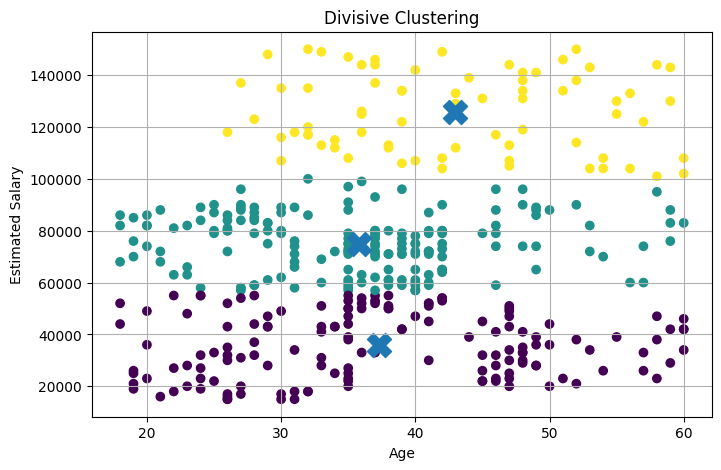

In [12]:
plt.figure(figsize=(8,5))

plt.scatter(
    X["Age"],
    X["EstimatedSalary"],
    c=clusters
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    s=300,
    marker="X"
)

plt.xlabel("Age")
plt.ylabel("Estimated Salary")

plt.title("Divisive Clustering")

plt.grid(True)

plt.show()

In [15]:
Z = linkage(
    X,
    method="complete"
)

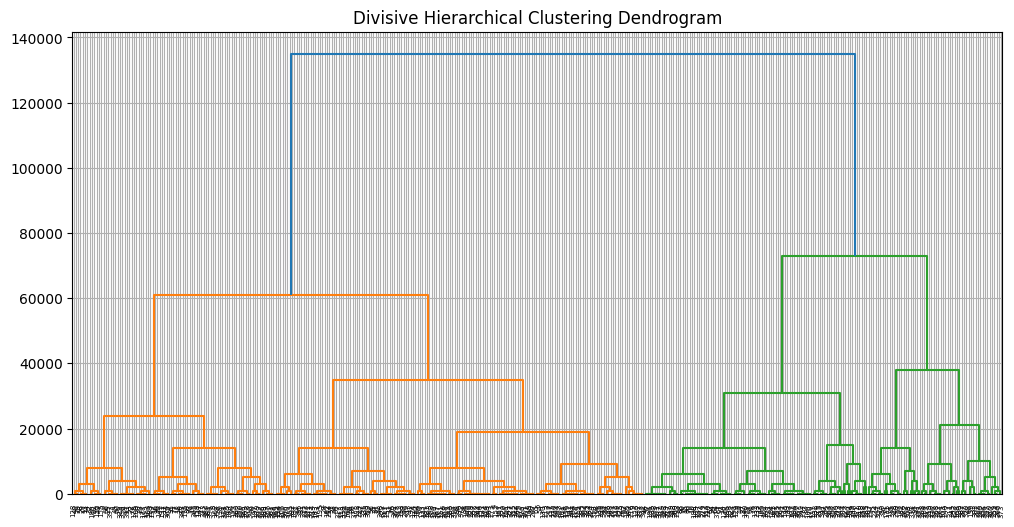

In [16]:
plt.figure(figsize=(12,6))

dendrogram(Z)

plt.title("Divisive Hierarchical Clustering Dendrogram")

plt.grid(True)

plt.show()

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [20]:
hc = AgglomerativeClustering(
    n_clusters=3
)
clusters = hc.fit_predict(X)

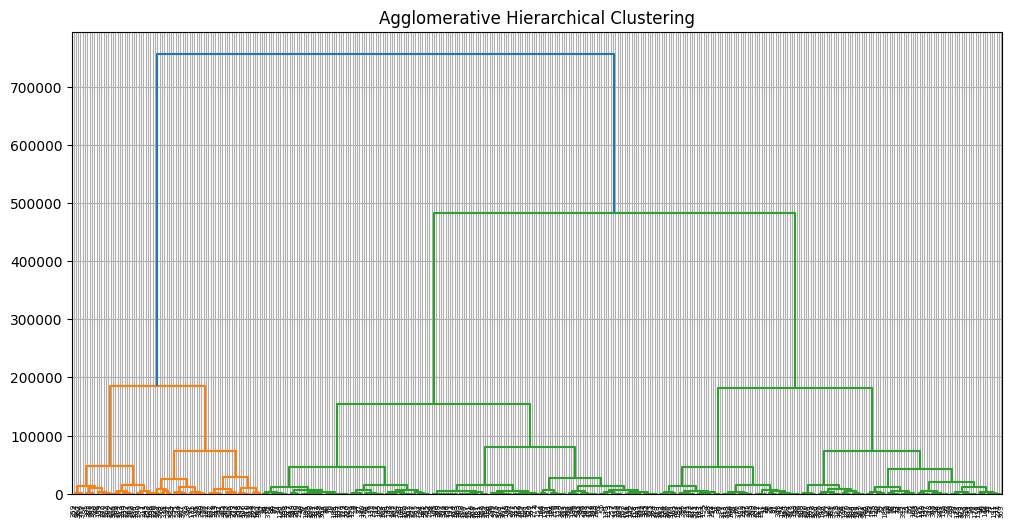

In [21]:
plt.figure(figsize=(12,6))
dendrogram(
    linkage(
        X,
        method="ward"
    )
)
plt.title("Agglomerative Hierarchical Clustering")
plt.grid(True)
plt.show()